In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
dataset=pd.read_csv("Churn_Modelling.csv")
dataset.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
dataset.drop(columns=["Surname","Geography","Gender","RowNumber","CustomerId"],axis=1,inplace=True)

In [4]:
dataset.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,42,2,0.00,1,1,1,101348.88,1
1,608,41,1,83807.86,1,0,1,112542.58,0
2,502,42,8,159660.80,3,1,0,113931.57,1
3,699,39,1,0.00,2,0,0,93826.63,0
4,850,43,2,125510.82,1,1,1,79084.10,0


In [5]:
dataset.shape

(10000, 9)

In [6]:
dataset.isnull().sum()

CreditScore        0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [7]:
input_data=dataset.iloc[:,:-1]
output_data=dataset["Exited"]

In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
ss=StandardScaler()
input_data=pd.DataFrame(ss.fit_transform(input_data),columns=input_data.columns)

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
x_train,x_test,y_train,y_test=train_test_split(input_data,output_data,test_size=0.2,random_state=42)

In [12]:
import tensorflow

In [92]:
from keras.layers import Dense,BatchNormalization
from keras.regularizers import L2
from keras.callbacks import EarlyStopping
from keras.models import Sequential

In [57]:
ann=Sequential()

In [93]:
ann.add(Dense(6,input_dim=8,activation="relu",kernel_regularizer=L2(l2=0.01)))
ann.add(BatchNormalization())
ann.add(Dense(4,activation="relu"))
ann.add(BatchNormalization())
ann.add(Dense(2,activation="relu"))
ann.add(BatchNormalization())
ann.add(Dense(1,activation="sigmoid"))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [94]:
ann.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [95]:
ann.fit(x_train,y_train,batch_size=100,epochs=60,validation_data=(x_test,y_test),callbacks=EarlyStopping())

Epoch 1/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8005 - loss: 0.6952 - val_accuracy: 0.8035 - val_loss: 0.6399
Epoch 2/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 680us/step - accuracy: 0.7936 - loss: 0.6271 - val_accuracy: 0.8035 - val_loss: 0.5814
Epoch 3/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step - accuracy: 0.7932 - loss: 0.5766 - val_accuracy: 0.8035 - val_loss: 0.5370
Epoch 4/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 657us/step - accuracy: 0.7987 - loss: 0.5398 - val_accuracy: 0.8035 - val_loss: 0.5083
Epoch 5/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 644us/step - accuracy: 0.7924 - loss: 0.5278 - val_accuracy: 0.8035 - val_loss: 0.5056
Epoch 6/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 627us/step - accuracy: 0.8024 - loss: 0.5082 - val_accuracy: 0.8035 - val_loss: 0.5574


In [96]:
prd1=ann.predict(x_train)
prd_data1=[]
for i in prd1:
    if i[0]>=0.5:
        prd_data1.append(1)
    else:
        prd_data1.append(0)

250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 198us/step


In [97]:
prd=ann.predict(x_test)
prd_data=[]
for i in prd:
    if i[0]>=0.5:
        prd_data.append(1)
    else:
        prd_data.append(0)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [98]:
from sklearn.metrics import accuracy_score

In [99]:
accuracy_score(y_test,prd_data)*100

80.35

In [100]:
accuracy_score(y_train,prd_data1)*100

79.45

Early stopping

In [101]:
training_accuracy=ann.history.history["accuracy"]
testing_accuracy=ann.history.history["val_accuracy"]

In [102]:
len(training_accuracy)

6

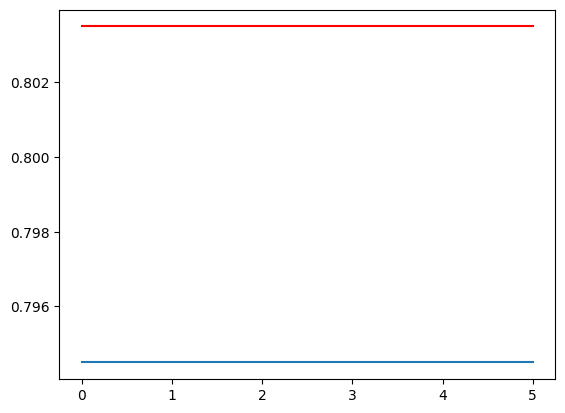

In [103]:
plt.plot([i for i in range(6)],training_accuracy)
plt.plot([i for i in range(6)],testing_accuracy,c="red")
plt.show()